# # 3//MODELE-EVALUATION-OPTIMISATION
   But de cette phase :
  * construire et comparer plusieurs modèles de Machine Learning à partir des données prétraitées, réaliser l'entraînement et les prédictions, évaluer leurs performances à l'aide des métriques Accuracy, Precision, Recall et F1-score (Macro et Weighted), analyser les matrices de confusion, puis effectuer l'optimisation des hyperparamètres du modèle Random Forest à l'aide de GridSearchCV (CV ≥ 5), afin de déterminer la meilleure configuration et d'améliorer les performances de prédiction des classes du Credit Score.

# 1/ Entraînement initial et comparaison globale

# MODELE ZERO-R

x_train : (80000, 56)
y_train : (80000, 1)
x_val : (20000, 56)
y_val : (20000, 1)
Temps d'entrainement : 0.055954933166503906
Temps de prédiction : 0.00017261505126953125
Accuracy: 0.5318
Precision Good : 0
Recall Good : 0.0
F1 Good : 0
Precision Standard : 0.5318
Recall Standard : 1.0
F1 Standard : 0.694346520433477
Precision Poor : 0
Recall Poor : 0.0
F1 Poor : 0
Macro F1-score : 0.23144884014449232
Weighted F1-score : 0.3692534795665231


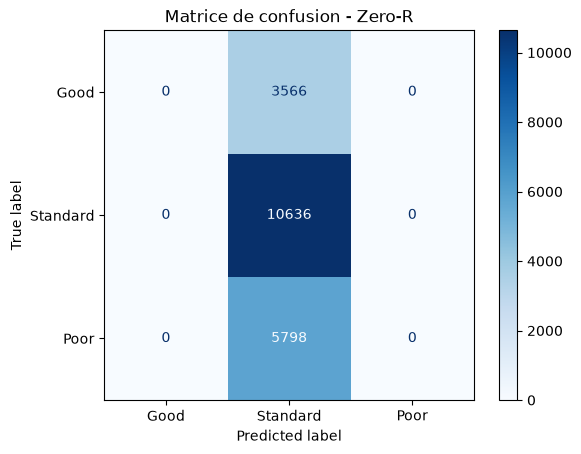

Résultats enregistrés ou mis  jour 


In [1]:
# Modèle-Zero-R
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
import os
 
# charger les données
 # données de entrainement
x_train =pd.read_csv ("../data/X_train_preprocessed.csv")
y_train =pd.read_csv ("../data/y_train.csv")
 # données de tests
x_val =pd.read_csv("../data/X_val_preprocessed.csv")
y_val =pd.read_csv("../data/y_val.csv")
 #verification de chargement
print("x_train :",x_train.shape )
print("y_train :",y_train.shape )
print("x_val :",x_val.shape )
print("y_val :",y_val.shape )
#prepare les classes
y_train_1d =y_train["Credit_Score"]
y_val_1d =y_val ["Credit_Score"]

#Crée le modèle
model_ZERO_R = DummyClassifier(strategy = "most_frequent")

# Entrainer et Calculer le temps d'exécusion
debut = time.time()
model_ZERO_R.fit(x_train, y_train_1d)
temps_entrainement = time.time() - debut
print("Temps d'entrainement :" ,temps_entrainement)

# Prédire et Calculer le temps d'exécusion
debut = time.time()
y_pred = model_ZERO_R.predict(x_val)
temps_prediction = time.time() - debut
print("Temps de prédiction :" ,temps_prediction)


#calcul les indicateurs de performance

 #Accuracy
accuracy =(y_val_1d == y_pred).mean()
print("Accuracy:", accuracy)

 # classe Good
  #Precision
pred_good =(y_pred == "Good") .sum()
if pred_good != 0:
   precision_good=((y_pred == "Good") & (y_val_1d == "Good")).sum()/pred_good
else:
  precision_good = 0
print("Precision Good :",precision_good)
  #Recall
recall_good = ((y_pred == "Good") & (y_val_1d == "Good")).sum() / (y_val_1d == "Good").sum()
print("Recall Good :", recall_good)
  #F1-score
if recall_good == 0 and precision_good == 0:
 F1_good = 0
else:
 F1_good = (2* recall_good * precision_good )/(recall_good + precision_good)
print("F1 Good :", F1_good)
  # Calculer le nombre de clients par classe
nombre_good = (y_val_1d == "Good").sum()
 
 #Classe Standard
  #precision
pred_standard =(y_pred == "Standard") .sum()
if pred_standard != 0:
 precision_standard=((y_pred == "Standard") & (y_val_1d == "Standard")).sum()/pred_standard
else :
 precision_standard = 0
print("Precision Standard :",precision_standard)
  #Recall
recall_standard = ((y_pred== "Standard") & (y_val_1d == "Standard")).sum() / (y_val_1d == "Standard").sum()
print("Recall Standard :", recall_standard)
  #F1-score
if recall_standard == 0 and precision_standard == 0 :
 F1_standard = 0
else:
 F1_standard = (2* recall_standard * precision_standard) / (recall_standard + precision_standard)
print("F1 Standard :", F1_standard)
  # Calculer le nombre de clients par classe
nombre_standard = (y_val_1d == "Standard").sum()
  
 #Classe Poor
  #precision
pred_poor =(y_pred == "Poor") .sum()
if pred_poor != 0: 
 precision_poor=((y_pred == "Poor") & (y_val_1d == "Poor")).sum()/pred_poor
else:
 precision_poor = 0 
print("Precision Poor :",precision_poor)
  #Recall
recall_poor = ((y_pred== "Poor") & (y_val_1d == "Poor")).sum() / (y_val_1d == "Poor").sum()
print("Recall Poor :", recall_poor)
  #F1-score
if recall_poor== 0 and precision_poor == 0:
 F1_poor = 0
else:
 F1_poor = (2* recall_poor * precision_poor) / (recall_poor + precision_poor)
print("F1 Poor :",  F1_poor) 
  # Calculer le nombre de clients par classe
nombre_poor = (y_val_1d == "Poor").sum()
 #Macro F1
Macro_F1 = (F1_good + F1_standard + F1_poor) / 3
print("Macro F1-score :", Macro_F1)

 #Weighted F1
Weighted_F1 = ((F1_good * nombre_good) + (F1_standard * nombre_standard) + (F1_poor * nombre_poor)) / (nombre_good + nombre_standard + nombre_poor)
print("Weighted F1-score :",Weighted_F1)


#afficher la matrice de confusion
Cm = confusion_matrix(
    y_val_1d,
    y_pred,
    labels=["Good", "Standard", "Poor"]
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=Cm,
    display_labels=["Good", "Standard", "Poor"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - Zero-R")
plt.show()

#Préparer les résultats
model_name = "model_ZERO_R"
resultats = {
    "Modele": model_name,
    "Accuracy": accuracy,
    "Precision_Good": precision_good,
    "Recall_Good": recall_good,
    "F1_Good": F1_good,
    "Precision_Standard": precision_standard,
    "Recall_Standard": recall_standard,
    "F1_Standard": F1_standard,
    "Precision_Poor": precision_poor,
    "Recall_Poor": recall_poor,
    "F1_Poor": F1_poor,
    "Macro_F1": Macro_F1,
    "Weighted_F1": Weighted_F1,
    "Temps_Entrainement": temps_entrainement,
    "Temps_Prediction": temps_prediction
}
# Créer la DataFrame
df = pd.DataFrame([resultats])
# Créer le dossier results
os.makedirs("../results", exist_ok=True)
# Fichier CSV
fichier = "../results/resultats_modeles.csv"
# Vérifier si le fichier existe
if os.path.exists(fichier):
 ancien = pd.read_csv(fichier)
 # Supprimer l'ancien résultat de ce modèle
 ancien = ancien[ancien["Modele"] != model_name]
 # Ajouter le nouveau résultat
 df = pd.concat([ancien, df], ignore_index=True)
# Enregistrer
df.to_csv(fichier, index=False)

print("Résultats enregistrés ou mis  jour ")

# Interprétation des résultas :
   Principe du Zero-R :
* C'est le classifieur de base le
plus simple ("dummy classifier"). Il n'apprend aucune relation dans les données ; il se contente de deviner toujours la classe la plus représentée dans le jeu de données (la classe Standard).
   Matrice de confusion :
* Le modèle a prédit la classe Standard pour les 20 000 échantillons de validation, ignorant complètement les classes Good et Poor.
   Performances :
* L'Accuracy de "53,18%" correspond exactement à la proportion de la classe "Standard" dans le jeu de données.
*Les métriques (Précision, Rappel, F1-score) pour Good et Poor sont à $0$ car aucune instance de ces classes n'a été prédite.  





# MODELE SVM

x_train : (80000, 56)
y_train : (80000, 1)
x_val : (20000, 56)
y_val : (20000, 1)
Temps d'entrainement : 920.9642806053162
Temps de prédiction : 154.33068799972534
Prédiction terminée !
Temps : 154.33068799972534 secondes
Accuracy: 0.68645
Precision Good : 0.5538922155688623
Recall Good : 0.6225462703309029
F1 Good : 0.58621600211249
Precision Standard : 0.7179280730005367
Recall Standard : 0.7545129748025573
F1 Standard : 0.7357660218208489
Precision Poor : 0.7237224761113419
Recall Poor : 0.600896860986547
F1 Poor : 0.656615152657369
Macro F1-score : 0.6595323921969026
Weighted F1-score : 0.6861554163363557


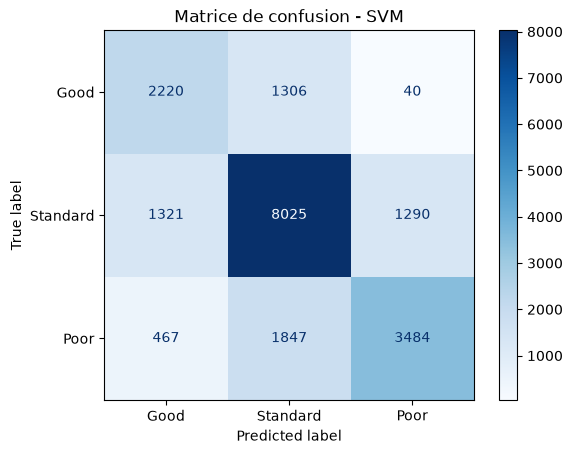

Résultats enregistrés ou mis a jour 


In [2]:
#Modèle-SVM
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
import time
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import os



# charger les donnéesnt
x_train =pd.read_csv ("../data/X_train_preprocessed.csv")
y_train =pd.read_csv ("../data/y_train.csv")
 # données de tests
x_val =pd.read_csv("../data/X_val_preprocessed.csv")
y_val =pd.read_csv("../data/y_val.csv")
 #verification de chargement
print("x_train :",x_train.shape )
print("y_train :",y_train.shape )
print("x_val :",x_val.shape )
print("y_val :",y_val.shape )
#prepare les classes
y_train_1d =y_train["Credit_Score"]
y_val_1d =y_val ["Credit_Score"]

#Crée le modèle
model_SVM = SVC(kernel="rbf", C=1, gamma="scale")

# Entrainer et Calculer le temps d'exécusion
debut = time.time()
model_SVM.fit(x_train, y_train_1d)
temps_entrainement = time.time() - debut
print("Temps d'entrainement :" ,temps_entrainement)

# Prédire et Calculer le temps d'exécusion
debut = time.time()
y_pred = model_SVM.predict(x_val)
temps_prediction = time.time() - debut
print("Temps de prédiction :" ,temps_prediction)
print("Prédiction terminée !")
print("Temps :", temps_prediction, "secondes")

#calcul les indicateurs de performance

 #Accuracy
accuracy =(y_val_1d == y_pred).mean()
print("Accuracy:", accuracy)

 # classe Good
  #Precision
pred_good =(y_pred == "Good") .sum()
if pred_good != 0:
   precision_good=((y_pred == "Good") & (y_val_1d == "Good")).sum()/pred_good
else:
  precision_good = 0
print("Precision Good :",precision_good)
  #Recall
recall_good = ((y_pred == "Good") & (y_val_1d == "Good")).sum() / (y_val_1d == "Good").sum()
print("Recall Good :", recall_good)
  #F1-score
if recall_good == 0 and precision_good == 0:
 F1_good = 0
else:
 F1_good = (2* recall_good * precision_good )/(recall_good + precision_good)
print("F1 Good :", F1_good)
  # Calculer le nombre de clients par classe
nombre_good = (y_val_1d == "Good").sum()
 
 #Classe Standard
  #precision
pred_standard =(y_pred == "Standard") .sum()
if pred_standard != 0:
 precision_standard=((y_pred == "Standard") & (y_val_1d == "Standard")).sum()/pred_standard
else :
 precision_standard = 0
print("Precision Standard :",precision_standard)
  #Recall
recall_standard = ((y_pred== "Standard") & (y_val_1d == "Standard")).sum() / (y_val_1d == "Standard").sum()
print("Recall Standard :", recall_standard)
  #F1-score
if recall_standard == 0 and precision_standard == 0 :
 F1_standard = 0
else:
 F1_standard = (2* recall_standard * precision_standard) / (recall_standard + precision_standard)
print("F1 Standard :", F1_standard)
  # Calculer le nombre de clients par classe
nombre_standard = (y_val_1d == "Standard").sum()
  
 #Classe Poor
  #precision
pred_poor =(y_pred == "Poor") .sum()
if pred_poor != 0: 
 precision_poor=((y_pred == "Poor") & (y_val_1d == "Poor")).sum()/pred_poor
else:
 precision_poor = 0 
print("Precision Poor :",precision_poor)
  #Recall
recall_poor = ((y_pred== "Poor") & (y_val_1d == "Poor")).sum() / (y_val_1d == "Poor").sum()
print("Recall Poor :", recall_poor)
  #F1-score
if recall_poor== 0 and precision_poor == 0:
 F1_poor = 0
else:
 F1_poor = (2* recall_poor * precision_poor) / (recall_poor + precision_poor)
print("F1 Poor :",  F1_poor) 
  # Calculer le nombre de clients par classe
nombre_poor = (y_val_1d == "Poor").sum()
 #Macro F1
Macro_F1 = (F1_good + F1_standard + F1_poor) / 3
print("Macro F1-score :", Macro_F1)

 #Weighted F1
Weighted_F1 = ((F1_good * nombre_good) + (F1_standard * nombre_standard) + (F1_poor * nombre_poor)) / (nombre_good + nombre_standard + nombre_poor)
print("Weighted F1-score :",Weighted_F1)


#afficher la matrice de confusion
Cm = confusion_matrix(
    y_val_1d,
    y_pred,
    labels=["Good", "Standard", "Poor"]
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=Cm,
    display_labels=["Good", "Standard", "Poor"]
)
disp.plot(cmap="Blues")
plt.title("Matrice de confusion - SVM")
plt.show()

#Préparer les résultats
model_name = "model_SVM"
resultats = {
    "Modele": model_name,
    "Accuracy": accuracy,
    "Precision_Good": precision_good,
    "Recall_Good": recall_good,
    "F1_Good": F1_good,
    "Precision_Standard": precision_standard,
    "Recall_Standard": recall_standard,
    "F1_Standard": F1_standard,
    "Precision_Poor": precision_poor,
    "Recall_Poor": recall_poor,
    "F1_Poor": F1_poor,
    "Macro_F1": Macro_F1,
    "Weighted_F1": Weighted_F1,
    "Temps_Entrainement": temps_entrainement,
    "Temps_Prediction": temps_prediction
}

# Créer la DataFrame
df = pd.DataFrame([resultats])
# Créer le dossier results
os.makedirs("../results", exist_ok=True)
# Fichier CSV
fichier = "../results/resultats_modeles.csv"
# Vérifier si le fichier existe
if os.path.exists(fichier):
 ancien = pd.read_csv(fichier)
 # Supprimer l'ancien résultat de ce modèle
 ancien = ancien[ancien["Modele"] != model_name]
 # Ajouter le nouveau résultat
 df = pd.concat([ancien, df], ignore_index=True)
# Enregistrer
df.to_csv(fichier, index=False)

print("Résultats enregistrés ou mis a jour ")

# Interprétation des résultas :
   Principe du SVM : 
* C'est un algorithme d'apprentissage supervisé qui cherche à trouver les hyperplans optimaux pour séparer au mieux les différentes classes dans l'espace multidimensionnel des caractéristiques.
   Matrice de confusion :
* Le modèle identifie correctement "13729" échantillons sur les "20000" du jeu de validation. On remarque toutefois un coût de calcul très élevé, avec un temps d'entraînement de "920" secondes et un temps de prédiction de "145" secondes.   
   Performances :
* L'Accuracy globale s'élève à "68,65%", ce qui témoigne d'une très bonne performance globale, comparable au Random Forest.  
* La classe Standard obtient les meilleures performances avec un score F1 de "0,74" ->"8025" bonnes prédictions.   
* La classe Poor s'en sort bien avec un score F1 de "0,66" -> "3484" bonnes prédictions, malgré des confusions avec la classe Standard ->"1847" erreurs.  
* La classe Good obtient un score F1 de "0,59" ->"2220" bonnes prédictions, avec des confusions notables où des instances sont classées à tort comme Standard ->"1306" erreurs.



# MODELE RANDOM FOREST

x_train : (80000, 56)
y_train : (80000, 1)
x_val : (20000, 56)
y_val : (20000, 1)
Temps d'entrainement : 2.401085615158081
Temps de prédiction : 0.06970858573913574
Accuracy: 0.6872
Precision Good : 0.5607180570221753
Recall Good : 0.5956253505328098
F1 Good : 0.577644819146043
Precision Standard : 0.7166068222621185
Recall Standard : 0.7505641218503196
F1 Standard : 0.733192505510654
Precision Poor : 0.7170741324921136
Recall Poor : 0.6272852707830286
F1 Poor : 0.66918123275069
Macro F1-score : 0.6600061858024623
Weighted F1-score : 0.6869014850587302


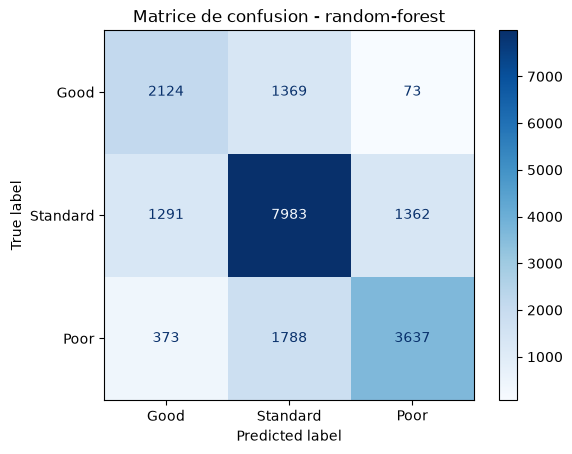

Résultats enregistrés ou mis a jour 


In [3]:
#Modèle-Random-Forest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import time
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import os


# charger les données
 # données de entrainement
x_train =pd.read_csv ("../data/X_train_preprocessed.csv")
y_train =pd.read_csv ("../data/y_train.csv")
 # données de tests
x_val =pd.read_csv("../data/X_val_preprocessed.csv")
y_val =pd.read_csv("../data/y_val.csv")
 #verification de chargement
print("x_train :",x_train.shape )
print("y_train :",y_train.shape )
print("x_val :",x_val.shape )
print("y_val :",y_val.shape )
#preparer les classes
y_train_1d =y_train["Credit_Score"]
y_val_1d =y_val ["Credit_Score"]

#Crée le modèle
model_RANDOM = RandomForestClassifier(n_estimators =30 , max_depth=15, random_state =42 ,  n_jobs=-1)
# Entrainer et Calculer le temps d'exécusion
debut = time.time()
model_RANDOM.fit(x_train, y_train_1d)
temps_entrainement = time.time() - debut
print("Temps d'entrainement :" ,temps_entrainement)

# Prédire et Calculer le temps d'exécusion
debut = time.time()
y_pred = model_RANDOM.predict(x_val)
temps_prediction = time.time() - debut
print("Temps de prédiction :" ,temps_prediction)


#calcul les indicateurs de performance

 #Accuracy
accuracy =(y_val_1d == y_pred).mean()
print("Accuracy:", accuracy)

 # classe Good
  #Precision
pred_good =(y_pred == "Good") .sum()
if pred_good != 0:
   precision_good=((y_pred == "Good") & (y_val_1d == "Good")).sum()/pred_good
else:
  precision_good = 0
print("Precision Good :",precision_good)
  #Recall
recall_good = ((y_pred == "Good") & (y_val_1d == "Good")).sum() / (y_val_1d == "Good").sum()
print("Recall Good :", recall_good)
  #F1-score
if recall_good == 0 and precision_good == 0:
 F1 = 0
else:
 F1_good = (2* recall_good * precision_good )/(recall_good + precision_good)
print("F1 Good :", F1_good)
  # Calculer le nombre de clients par classe
nombre_good = (y_val_1d == "Good").sum()
 
 #Classe Standard
  #precision
pred_standard =(y_pred == "Standard") .sum()
if pred_standard != 0:
 precision_standard=((y_pred == "Standard") & (y_val_1d == "Standard")).sum()/pred_standard
else :
 precision_standard = 0
print("Precision Standard :",precision_standard)
  #Recall
recall_standard = ((y_pred== "Standard") & (y_val_1d == "Standard")).sum() / (y_val_1d == "Standard").sum()
print("Recall Standard :", recall_standard)
  #F1-score
if recall_standard == 0 and precision_standard == 0 :
 F1 = 0
else:
 F1_standard = (2* recall_standard * precision_standard) / (recall_standard + precision_standard)
print("F1 Standard :", F1_standard)
  # Calculer le nombre de clients par classe
nombre_standard = (y_val_1d == "Standard").sum()
  
 #Classe Poor
  #precision
pred_poor =(y_pred == "Poor") .sum()
if pred_poor != 0: 
 precision_poor=((y_pred == "Poor") & (y_val_1d == "Poor")).sum()/pred_poor
else:
 precision_poor = 0 
print("Precision Poor :",precision_poor)
  #Recall
recall_poor = ((y_pred== "Poor") & (y_val_1d == "Poor")).sum() / (y_val_1d == "Poor").sum()
print("Recall Poor :", recall_poor)
  #F1-score
if recall_poor== 0 and precision_poor == 0:
 F1 = 0
else:
 F1_poor = (2* recall_poor * precision_poor) / (recall_poor + precision_poor)
print("F1 Poor :",  F1_poor) 
  # Calculer le nombre de clients par classe
nombre_poor = (y_val_1d == "Poor").sum()
 #Macro F1
Macro_F1 = (F1_good + F1_standard + F1_poor) / 3
print("Macro F1-score :", Macro_F1)

 #Weighted F1
Weighted_F1 = ((F1_good * nombre_good) + (F1_standard * nombre_standard) + (F1_poor * nombre_poor)) / (nombre_good + nombre_standard + nombre_poor)
print("Weighted F1-score :",Weighted_F1)


#afficher la matrice de confusion
Cm = confusion_matrix(
    y_val_1d,
    y_pred,
    labels=["Good", "Standard", "Poor"]
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=Cm,
    display_labels=["Good", "Standard", "Poor"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - random-forest")
plt.show()

#Préparer les résultats
model_name = "model_RANDOM"
resultats = {
    "Modele": model_name,
    "Accuracy": accuracy,
    "Precision_Good": precision_good,
    "Recall_Good": recall_good,
    "F1_Good": F1_good,
    "Precision_Standard": precision_standard,
    "Recall_Standard": recall_standard,
    "F1_Standard": F1_standard,
    "Precision_Poor": precision_poor,
    "Recall_Poor": recall_poor,
    "F1_Poor": F1_poor,
    "Macro_F1": Macro_F1,
    "Weighted_F1": Weighted_F1,
    "Temps_Entrainement": temps_entrainement,
    "Temps_Prediction": temps_prediction
}

# Créer la DataFrame
df = pd.DataFrame([resultats])
# Créer le dossier results
os.makedirs("../results", exist_ok=True)
# Fichier CSV
fichier = "../results/resultats_modeles.csv"
# Vérifier si le fichier existe
if os.path.exists(fichier):
 ancien = pd.read_csv(fichier)
 # Supprimer l'ancien résultat de ce modèle
 ancien = ancien[ancien["Modele"] != model_name]
 # Ajouter le nouveau résultat
 df = pd.concat([ancien, df], ignore_index=True)
# Enregistrer
df.to_csv(fichier, index=False)

print("Résultats enregistrés ou mis a jour ")

# Interprétation des résultas :
   Principe du Random Forest :
* C'est un algorithme d'apprentissage supervisé basé sur un ensemble d'arbres de décision. Il combine les prédictions de plusieurs arbres entraînés sur différentes parties des données pour prendre une décision globale plus robuste et précise.
   Matrice de confusion : 
* Le modèle répartit ses prédictions entre les trois classes. Il classe correctement "13744" échantillons sur les "20000" du jeu de validation ("2124"-> "Good", "7983"-> "Standard" et "3637"-> "Poor").
   Performances :
* L'Accuracy s'élève à "68,72%", ce qui signifie que le modèle classe correctement un peu plus des deux tiers des données.
* La classe Standard obtient les meilleures métriques (F1-score de "0,73").
* La classe Poor est également bien détectée (F1-score de "0,67"). 
* La classe Good présente plus de confusions (F1-score de "0,58"), car "1369" échantillons "Good" ont été prédits à tort comme "Standard".




# MODELE NAIVE BAYES

x_train : (80000, 56)
y_train : (80000, 1)
x_val : (20000, 56)
y_val : (20000, 1)
Temps d'entrainement : 0.2654378414154053
Temps de prédiction : 0.06603121757507324
Accuracy: 0.5786
Precision Good : 0.4004910653389715
Recall Good : 0.823331463825014
F1 Good : 0.5388639074974764
Precision Standard : 0.8254089007227082
Recall Standard : 0.40804813839789394
F1 Standard : 0.5461180319617466
Precision Poor : 0.5796788557549588
Recall Poor : 0.7409451535012073
F1 Poor : 0.6504655916420622
Macro F1-score : 0.578482510367095
Weighted F1-score : 0.5750749791210906


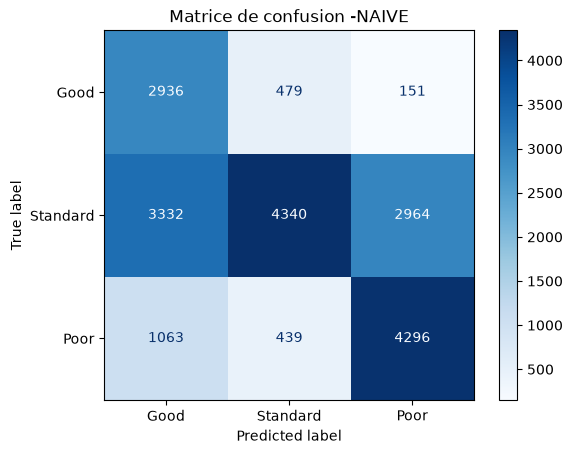

Résultats enregistrés ou mis a jour 


In [4]:
#Modèle-Naive-Bayes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
import time
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
import os


# charger les données
 # données de entrainement
x_train =pd.read_csv ("../data/X_train_preprocessed.csv")
y_train =pd.read_csv ("../data/y_train.csv")
 # données de tests
x_val =pd.read_csv("../data/X_val_preprocessed.csv")
y_val =pd.read_csv("../data/y_val.csv")
 #verification de chargement
print("x_train :",x_train.shape )
print("y_train :",y_train.shape )
print("x_val :",x_val.shape )
print("y_val :",y_val.shape )
#prepare les classes
y_train_1d =y_train["Credit_Score"]
y_val_1d =y_val ["Credit_Score"]

#Crée le modèle
model_NAIVE = GaussianNB()


# Entrainer et Calculer le temps d'exécusion
debut = time.time()
model_NAIVE.fit(x_train, y_train_1d)
temps_entrainement = time.time() - debut
print("Temps d'entrainement :" ,temps_entrainement)

# Prédire et Calculer le temps d'exécusion
debut = time.time()
y_pred = model_NAIVE.predict(x_val)
temps_prediction = time.time() - debut
print("Temps de prédiction :" ,temps_prediction)

#calcul les indicateurs de performance

 #Accuracy
accuracy =(y_val_1d == y_pred).mean()
print("Accuracy:", accuracy)

 # classe Good
  #Precision
pred_good =(y_pred == "Good") .sum()
if pred_good != 0:
   precision_good=((y_pred == "Good") & (y_val_1d == "Good")).sum()/pred_good
else:
  precision_good = 0
print("Precision Good :",precision_good)
  #Recall
recall_good = ((y_pred == "Good") & (y_val_1d == "Good")).sum() / (y_val_1d == "Good").sum()
print("Recall Good :", recall_good)
  #F1-score
if recall_good == 0 and precision_good == 0:
 F1 = 0
else:
 F1_good = (2* recall_good * precision_good )/(recall_good + precision_good)
print("F1 Good :", F1_good)
  # Calculer le nombre de clients par classe
nombre_good = (y_val_1d == "Good").sum()
 
 #Classe Standard
  #precision
pred_standard =(y_pred == "Standard") .sum()
if pred_standard != 0:
 precision_standard=((y_pred == "Standard") & (y_val_1d == "Standard")).sum()/pred_standard
else :
 precision_standard = 0
print("Precision Standard :",precision_standard)
  #Recall
recall_standard = ((y_pred== "Standard") & (y_val_1d == "Standard")).sum() / (y_val_1d == "Standard").sum()
print("Recall Standard :", recall_standard)
  #F1-score
if recall_standard == 0 and precision_standard == 0 :
 F1 = 0
else:
 F1_standard = (2* recall_standard * precision_standard) / (recall_standard + precision_standard)
print("F1 Standard :", F1_standard)
  # Calculer le nombre de clients par classe
nombre_standard = (y_val_1d == "Standard").sum()
  
 #Classe Poor
  #precision
pred_poor =(y_pred == "Poor") .sum()
if pred_poor != 0: 
 precision_poor=((y_pred == "Poor") & (y_val_1d == "Poor")).sum()/pred_poor
else:
 precision_poor = 0 
print("Precision Poor :",precision_poor)
  #Recall
recall_poor = ((y_pred== "Poor") & (y_val_1d == "Poor")).sum() / (y_val_1d == "Poor").sum()
print("Recall Poor :", recall_poor)
  #F1-score
if recall_poor== 0 and precision_poor == 0:
 F1 = 0
else:
 F1_poor = (2* recall_poor * precision_poor) / (recall_poor + precision_poor)
print("F1 Poor :",  F1_poor) 
  # Calculer le nombre de clients par classe
nombre_poor = (y_val_1d == "Poor").sum()
 #Macro F1
Macro_F1 = (F1_good + F1_standard + F1_poor) / 3
print("Macro F1-score :", Macro_F1)

 #Weighted F1
Weighted_F1 = ((F1_good * nombre_good) + (F1_standard * nombre_standard) + (F1_poor * nombre_poor)) / (nombre_good + nombre_standard + nombre_poor)
print("Weighted F1-score :",Weighted_F1)


#afficher la matrice de confusion
Cm = confusion_matrix(
    y_val_1d,
    y_pred,
    labels=["Good", "Standard", "Poor"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=Cm,
    display_labels=["Good", "Standard", "Poor"]
)
disp.plot(cmap="Blues")
plt.title("Matrice de confusion -NAIVE")
plt.show()

#Préparer les résultats
model_name = "model_NAIVE"
resultats = {
    "Modele": model_name,
    "Accuracy": accuracy,
    "Precision_Good": precision_good,
    "Recall_Good": recall_good,
    "F1_Good": F1_good,
    "Precision_Standard": precision_standard,
    "Recall_Standard": recall_standard,
    "F1_Standard": F1_standard,
    "Precision_Poor": precision_poor,
    "Recall_Poor": recall_poor,
    "F1_Poor": F1_poor,
    "Macro_F1": Macro_F1,
    "Weighted_F1": Weighted_F1,
    "Temps_Entrainement": temps_entrainement,
    "Temps_Prediction": temps_prediction
}

# Créer la DataFrame
df = pd.DataFrame([resultats])
# Créer le dossier results
os.makedirs("../results", exist_ok=True)
# Fichier CSV
fichier = "../results/resultats_modeles.csv"
# Vérifier si le fichier existe
if os.path.exists(fichier):
 ancien = pd.read_csv(fichier)
 # Supprimer l'ancien résultat de ce modèle
 ancien = ancien[ancien["Modele"] != model_name]
 # Ajouter le nouveau résultat
 df = pd.concat([ancien, df], ignore_index=True)
# Enregistrer
df.to_csv(fichier, index=False)

print("Résultats enregistrés ou mis a jour ")



# Interprétation des résultas:
   Principe du Naive Bayes :
* C'est un algorithme de classification probabiliste fondé sur le théorème de Bayes. Il repose sur l'hypothèse « naïve » que toutes les variables/caractéristiques sont totalement indépendantes les unes des autres sachant la classe.
   Matrice de confusion : 
* Le modèle parvient à classer correctement "11572" échantillons sur les "20\,000" de validation. Cependant, il montre une très fort penchant à sur-prédire les classes extrêmes ("Good" et "Poor") au détriment de la classe centrale ("Standard").
   Performances :
* L'Accuracy est de "57,86".   La classe Poor enregistre la meilleure détection globale avec un F1-score de 0,65 et un rappel de "74,09%" ("4296" bonnes prédictions).  
* La classe Good obtient un très bon rappel ("82,33%"), mais une faible précision ("40,05%") en raison de nombreux faux positifs ("3332" échantillons "Standard" prédits à tort comme "Good").   
* La classe Standard souffre d'un faible rappel ("40,80%"), car une grande partie de ses instances est dispersée à tort vers "Good" ->"3332" et "Poor" ->"2964".

# MODELE KNN

x_train : (80000, 56)
y_train : (80000, 1)
x_val : (20000, 56)
y_val : (20000, 1)
Temps d'entrainement : 0.14701414108276367
Temps de prédiction : 4.922593355178833
Accuracy: 0.62785
Precision Good : 0.47432950191570883
Recall Good : 0.5207515423443634
F1 Good : 0.49645769282181523
Precision Standard : 0.6855717716608165
Recall Standard : 0.6978187288454306
F1 Standard : 0.6916410399776349
Precision Poor : 0.6233124168092793
Recall Poor : 0.5653673680579511
F1 Poor : 0.5929275572035815
Macro F1-score : 0.5936754300010105
Weighted F1-score : 0.6282228105235542


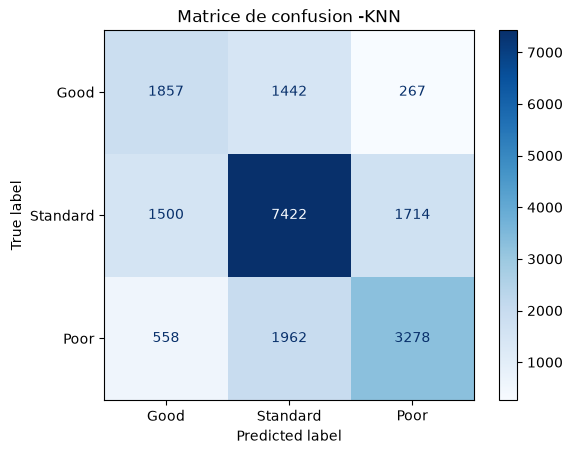

Résultats enregistrés ou mis a jour 


In [ ]:
# modèle-KNN
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
import time
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import os


# charger les données
 # données de entrainement
x_train =pd.read_csv ("../data/X_train_preprocessed.csv")
y_train =pd.read_csv ("../data/y_train.csv")
 # données de tests
x_val =pd.read_csv("../data/X_val_preprocessed.csv")
y_val =pd.read_csv("../data/y_val.csv")
 #verification de chargement
print("x_train :",x_train.shape )
print("y_train :",y_train.shape )
print("x_val :",x_val.shape )
print("y_val :",y_val.shape )
#prepare les classes
y_train_1d =y_train["Credit_Score"]
y_val_1d =y_val ["Credit_Score"]

#Crée le modèle
model_KNN = KNeighborsClassifier(n_neighbors = 5)

# Entrainer et Calculer le temps d'exécusion
debut = time.time()
model_KNN.fit(x_train, y_train_1d)
temps_entrainement = time.time() - debut
print("Temps d'entrainement :" ,temps_entrainement)

# Prédire et Calculer le temps d'exécusion
debut = time.time()
y_pred = model_KNN.predict(x_val)
temps_prediction = time.time() - debut
print("Temps de prédiction :" ,temps_prediction)

#calcul les indicateurs de performance

 #Accuracy
accuracy =(y_val_1d == y_pred).mean()
print("Accuracy:", accuracy)

 # classe Good
  #Precision
pred_good =(y_pred == "Good") .sum()
if pred_good != 0:
   precision_good=((y_pred == "Good") & (y_val_1d == "Good")).sum()/pred_good
else:
  precision_good = 0
print("Precision Good :",precision_good)
  #Recall
recall_good = ((y_pred == "Good") & (y_val_1d == "Good")).sum() / (y_val_1d == "Good").sum()
print("Recall Good :", recall_good)
  #F1-score
if recall_good == 0 and precision_good == 0:
 F1 = 0
else:
 F1_good = (2* recall_good * precision_good )/(recall_good + precision_good)
print("F1 Good :", F1_good)
  # Calculer le nombre de clients par classe
nombre_good = (y_val_1d == "Good").sum()
 
 #Classe Standard
  #precision
pred_standard =(y_pred == "Standard") .sum()
if pred_standard != 0:
 precision_standard=((y_pred == "Standard") & (y_val_1d == "Standard")).sum()/pred_standard
else :
 precision_standard = 0
print("Precision Standard :",precision_standard)
  #Recall
recall_standard = ((y_pred== "Standard") & (y_val_1d == "Standard")).sum() / (y_val_1d == "Standard").sum()
print("Recall Standard :", recall_standard)
  #F1-score
if recall_standard == 0 and precision_standard == 0 :
 F1 = 0
else:
 F1_standard = (2* recall_standard * precision_standard) / (recall_standard + precision_standard)
print("F1 Standard :", F1_standard)
  # Calculer le nombre de clients par classe
nombre_standard = (y_val_1d == "Standard").sum()
  
 #Classe Poor
  #precision
pred_poor =(y_pred == "Poor") .sum()
if pred_poor != 0: 
 precision_poor=((y_pred == "Poor") & (y_val_1d == "Poor")).sum()/pred_poor
else:
 precision_poor = 0 
print("Precision Poor :",precision_poor)
  #Recall
recall_poor = ((y_pred== "Poor") & (y_val_1d == "Poor")).sum() / (y_val_1d == "Poor").sum()
print("Recall Poor :", recall_poor)
  #F1-score
if recall_poor== 0 and precision_poor == 0:
 F1 = 0
else:
 F1_poor = (2* recall_poor * precision_poor) / (recall_poor + precision_poor)
print("F1 Poor :",  F1_poor) 
  # Calculer le nombre de clients par classe
nombre_poor = (y_val_1d == "Poor").sum()
 #Macro F1
Macro_F1 = (F1_good + F1_standard + F1_poor) / 3
print("Macro F1-score :", Macro_F1)

 #Weighted F1
Weighted_F1 = ((F1_good * nombre_good) + (F1_standard * nombre_standard) + (F1_poor * nombre_poor)) / (nombre_good + nombre_standard + nombre_poor)
print("Weighted F1-score :",Weighted_F1)


#afficher la matrice de confusion
Cm = confusion_matrix(
    y_val_1d,
    y_pred,
    labels=["Good", "Standard", "Poor"]
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=Cm,
    display_labels=["Good", "Standard", "Poor"]
)
disp.plot(cmap="Blues")
plt.title("Matrice de confusion -KNN")
plt.show()

#Préparer les résultats
model_name = "model_KNN"
resultats = {
    "Modele": model_name,
    "Accuracy": accuracy,
    "Precision_Good": precision_good,
    "Recall_Good": recall_good,
    "F1_Good": F1_good,
    "Precision_Standard": precision_standard,
    "Recall_Standard": recall_standard,
    "F1_Standard": F1_standard,
    "Precision_Poor": precision_poor,
    "Recall_Poor": recall_poor,
    "F1_Poor": F1_poor,
    "Macro_F1": Macro_F1,
    "Weighted_F1": Weighted_F1,
    "Temps_Entrainement": temps_entrainement,
    "Temps_Prediction": temps_prediction
}

# Créer la DataFrame
df = pd.DataFrame([resultats])
# Créer le dossier results
os.makedirs("../results", exist_ok=True)
# Fichier CSV
fichier = "../results/resultats_modeles.csv"
# Vérifier si le fichier existe
if os.path.exists(fichier):
 ancien = pd.read_csv(fichier)
 # Supprimer l'ancien résultat de ce modèle
 ancien = ancien[ancien["Modele"] != model_name]
 # Ajouter le nouveau résultat
 df = pd.concat([ancien, df], ignore_index=True)
# Enregistrer
df.to_csv(fichier, index=False)

print("Résultats enregistrés ou mis a jour ")

# Interprétation des résultas:
   Principe du KNN : 
* C'est un algorithme d'apprentissage paresseux (lazy learner) qui classifie une nouvelle observation en se basant sur la majorité des classes de ses ""k"" voisins les plus proches dans l'espace multidimensionnel des 56 caractéristiques.
   Matrice de confusion : 
* Le modèle répartit ses prédictions et identifie correctement "12557" échantillons sur les "20000" de validation. On observe toutefois un temps de prédiction  élevé "4.92" secondes, ce qui est typique du KNN car il doit calculer la distance avec toutes les données d'entraînement pour chaque prédiction.  
  Performances :
* L'Accuracy globale s'élève à "62,79%", ce qui montre une performance correcte, supérieure aux baselines naïves mais en deçà du Random Forest.  
* La classe Standard obtient les meilleurs résultats avec un score F1 de "0,69" ->"7422" bonnes prédictions. 
* La classe Poor s'en sort honorablement avec un score F1 de "0,59" -> "3278" bonnes prédictions, malgré des confusions notables avec la classe Standard ->"1962" erreurs. 
* La classe Good est la plus délicate avec un score F1 de "0,50", subissant des confusions fréquentes où des échantillons sont classés à tort comme Standard ->"1442" erreurs.

# MODELE DECISION TREE

x_train : (80000, 56)
y_train : (80000, 1)
x_val : (20000, 56)
y_val : (20000, 1)
Temps d'entrainement : 3.078590154647827
Temps de prédiction : 0.020359039306640625
Accuracy: 0.59165
Precision Good : 0.4586870401810979
Recall Good : 0.4545709478407179
F1 Good : 0.45661971830985915
Precision Standard : 0.6547155827311469
Recall Standard : 0.6644415193681835
F1 Standard : 0.6595426971535231
Precision Poor : 0.5544781382228491
Recall Poor : 0.5424284235943428
F1 Poor : 0.5483870967741934
Macro F1-score : 0.5548498374125251
Weighted F1-score : 0.5911375214757302


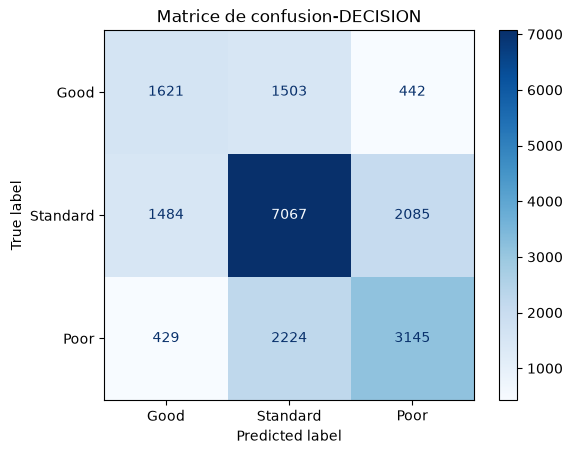

Résultats enregistrés ou mis a jour 


In [ ]:
#modèle-decision-tree
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
import time
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import os


# charger les données
 # données de entrainement
x_train =pd.read_csv ("../data/X_train_preprocessed.csv")
y_train =pd.read_csv ("../data/y_train.csv")
 # données de tests
x_val =pd.read_csv("../data/X_val_preprocessed.csv")
y_val =pd.read_csv("../data/y_val.csv")
 #verification de chargement
print("x_train :",x_train.shape )
print("y_train :",y_train.shape )
print("x_val :",x_val.shape )
print("y_val :",y_val.shape )
#preparer les classes
y_train_1d =y_train["Credit_Score"]
y_val_1d =y_val ["Credit_Score"]

#Crée le modèle
model_DECISION_TREE = DecisionTreeClassifier(random_state = 42)

# Entrainer et Calculer le temps d'exécusion
debut = time.time()
model_DECISION_TREE.fit(x_train, y_train_1d)
temps_entrainement = time.time() - debut
print("Temps d'entrainement :" ,temps_entrainement)

# Prédire et Calculer le temps d'exécusion
debut = time.time()
y_pred = model_DECISION_TREE.predict(x_val)
temps_prediction = time.time() - debut
print("Temps de prédiction :" ,temps_prediction)


#calcul les indicateurs de performance

 #Accuracy
accuracy =(y_val_1d == y_pred).mean()
print("Accuracy:", accuracy)

 # classe Good
  #Precision
pred_good =(y_pred == "Good") .sum()
if pred_good != 0:
   precision_good=((y_pred == "Good") & (y_val_1d == "Good")).sum()/pred_good
else:
  precision_good = 0
print("Precision Good :",precision_good)
  #Recall
recall_good = ((y_pred == "Good") & (y_val_1d == "Good")).sum() / (y_val_1d == "Good").sum()
print("Recall Good :", recall_good)
  #F1-score
if recall_good == 0 and precision_good == 0:
 F1 = 0
else:
 F1_good = (2* recall_good * precision_good )/(recall_good + precision_good)
print("F1 Good :", F1_good)
  # Calculer le nombre de clients par classe
nombre_good = (y_val_1d == "Good").sum()
 
 #Classe Standard
  #precision
pred_standard =(y_pred == "Standard") .sum()
if pred_standard != 0:
 precision_standard=((y_pred == "Standard") & (y_val_1d == "Standard")).sum()/pred_standard
else :
 precision_standard = 0
print("Precision Standard :",precision_standard)
  #Recall
recall_standard = ((y_pred== "Standard") & (y_val_1d == "Standard")).sum() / (y_val_1d == "Standard").sum()
print("Recall Standard :", recall_standard)
  #F1-score
if recall_standard == 0 and precision_standard == 0 :
 F1 = 0
else:
 F1_standard = (2* recall_standard * precision_standard) / (recall_standard + precision_standard)
print("F1 Standard :", F1_standard)
  # Calculer le nombre de clients par classe
nombre_standard = (y_val_1d == "Standard").sum()
  
 #Classe Poor
  #precision
pred_poor =(y_pred == "Poor") .sum()
if pred_poor != 0: 
 precision_poor=((y_pred == "Poor") & (y_val_1d == "Poor")).sum()/pred_poor
else:
 precision_poor = 0 
print("Precision Poor :",precision_poor)
  #Recall
recall_poor = ((y_pred== "Poor") & (y_val_1d == "Poor")).sum() / (y_val_1d == "Poor").sum()
print("Recall Poor :", recall_poor)
  #F1-score
if recall_poor== 0 and precision_poor == 0:
 F1 = 0
else:
 F1_poor = (2* recall_poor * precision_poor) / (recall_poor + precision_poor)
print("F1 Poor :",  F1_poor) 
  # Calculer le nombre de clients par classe
nombre_poor = (y_val_1d == "Poor").sum()
 #Macro F1
Macro_F1 = (F1_good + F1_standard + F1_poor) / 3
print("Macro F1-score :", Macro_F1)

 #Weighted F1
Weighted_F1 = ((F1_good * nombre_good) + (F1_standard * nombre_standard) + (F1_poor * nombre_poor)) / (nombre_good + nombre_standard + nombre_poor)
print("Weighted F1-score :",Weighted_F1)


#afficher la matrice de confusion
Cm = confusion_matrix(
    y_val_1d,
    y_pred,
    labels=["Good", "Standard", "Poor"]
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=Cm,
    display_labels=["Good", "Standard", "Poor"]
)
disp.plot(cmap="Blues")
plt.title("Matrice de confusion-DECISION")
plt.show()

#Préparer les résultats
model_name = "model_DECISION_TREE"
resultats = {
    "Modele": model_name,
    "Accuracy": accuracy,
    "Precision_Good": precision_good,
    "Recall_Good": recall_good,
    "F1_Good": F1_good,
    "Precision_Standard": precision_standard,
    "Recall_Standard": recall_standard,
    "F1_Standard": F1_standard,
    "Precision_Poor": precision_poor,
    "Recall_Poor": recall_poor,
    "F1_Poor": F1_poor,
    "Macro_F1": Macro_F1,
    "Weighted_F1": Weighted_F1,
    "Temps_Entrainement": temps_entrainement,
    "Temps_Prediction": temps_prediction
}

# Créer la DataFrame
df = pd.DataFrame([resultats])
# Créer le dossier results
os.makedirs("../results", exist_ok=True)
# Fichier CSV
fichier = "../results/resultats_modeles.csv"
# Vérifier si le fichier existe
if os.path.exists(fichier):
 ancien = pd.read_csv(fichier)
 # Supprimer l'ancien résultat de ce modèle
 ancien = ancien[ancien["Modele"] != model_name]
 # Ajouter le nouveau résultat
 df = pd.concat([ancien, df], ignore_index=True)
# Enregistrer
df.to_csv(fichier, index=False)

print("Résultats enregistrés ou mis a jour ")

# Interprétation des résultas:
   Principe de l'Arbre de décision :
* C'est un algorithme d'apprentissage supervisé qui structure les données sous forme de hiérarchie de règles de décision (tests sur les 56 caractéristiques) pour aboutir à une classification. 
   Matrice de confusion : 
* Le modèle répartit ses prédictions et identifie correctement "11833" échantillons sur les "20000" du jeu de validation. Il montre un temps d'entraînement de "3.07" secondes pour un temps de prédiction très rapide de "0,02" seconde. 
   Performances :
* L'Accuracy globale s'élève à   "59,165%", ce qui indique des performances modérées, supérieures aux approches purement naïves mais en retrait face à des modèles plus robustes comme le Random Forest. 
* La classe Standard obtient les résultats les plus satisfaisants avec un score F1 de "0,66" -> "7067" bonnes prédictions, profitant de son volume de données plus important.  
* La classe Poor enregistre un score F1 de "0,55" ->  "3145" bonnes prédictions, avec des confusions notables où des instances sont classées à tort dans la catégorie Standard "2224" erreurs.  
* La classe Good présente les plus grandes difficultés avec un score F1 de "0,46" ->"621" bonnes prédictions, subissant de nombreuses confusions avec la classe Standard ->"1503" erreurs. 


# 2/ COMPARAISON DES MODELES

In [12]:
import pandas as pd

resultats = pd.read_csv("../results/resultats_modeles.csv")

display(resultats)

,Modele,Accuracy,Precision_Good,Recall_Good,F1_Good,Precision_Standard,Recall_Standard,F1_Standard,Precision_Poor,Recall_Poor,F1_Poor,Macro_F1,Weighted_F1,Temps_Entrainement,Temps_Prediction
0,model_ZERO_R,0.53180,0.000000,0.000000,0.000000,0.531800,1.000000,0.694347,0.000000,0.000000,0.000000,0.231449,0.369253,0.055955,0.000173
1,model_SVM,0.68645,0.553892,0.622546,0.586216,0.717928,0.754513,0.735766,0.723722,0.600897,0.656615,0.659532,0.686155,920.964281,154.330688
2,model_RANDOM,0.68720,0.560718,0.595625,0.577645,0.716607,0.750564,0.733193,0.717074,0.627285,0.669181,0.660006,0.686901,2.401086,0.069709
3,model_NAIVE,0.57860,0.400491,0.823331,0.538864,0.825409,0.408048,0.546118,0.579679,0.740945,0.650466,0.578483,0.575075,0.265438,0.066031
4,model_KNN,0.62785,0.474330,0.520752,0.496458,0.685572,0.697819,0.691641,0.623312,0.565367,0.592928,0.593675,0.628223,0.147014,4.922593
5,model_DECISION_TREE,0.59165,0.458687,0.454571,0.456620,0.654716,0.664442,0.659543,0.554478,0.542428,0.548387,0.554850,0.591138,3.078590,0.020359


# Analyse Comparative Récapitulative :
   Principe de l'évaluation comparative :
* L'objectif de cette synthèse est d'analyser le compromis entre la précision algorithmique et l'efficacité computationnelle (temps d'exécution) pour sélectionner le modèle optimal.
   Modèles performants: 
* Random Forest et SVM obtiennent les meilleurs scores de classification, atteignant tous deux environ "68,7%" d'Accuracy et un Weighted F1-score de "0,686".    
* Différence majeure de coût numérique :
    * Random Forest s'entraîne en seulement "2.40" secondes et prédit en "0,069" seconde.
    * SVM nécessite un temps d'entraînement de "920" secondes( ~ 15,4 minutes) et un temps de prédiction de "154.33" secondes. 
    Modèles intermédiaires et baselines :

* KNN offre des performances correctes <"62,785%" d'accuracy>, mais souffre d'un temps de prédiction élevé <"4.92" secondes>.
* Arbre de décision seul plafonne à <"59,165%"> d'accuracy, souffrant du risque de surapprentissage par rapport aux forêts d'arbres.
* Naive Bayes <"57,86%"> et Zero-R <"53,18%"> servent de références de base (baselines), validant que tous les modèles complexes apprennent de manière effective.



# CONCULSION "avant optimisation":
"" Le modèle Random Forest "" s'impose comme la meilleure solution pratique. Il offre la meilleure précision globale tout en conservant une vitesse d'exécution optimale pour le déploiement.

# 3/Optimisation des hyperparamètres et  Validation croisée

# Validation Croisée  "StratifiedKFold"

Pli 1 -> Accuracy: 0.7508 | F1 Macro: 0.7331
Pli 2 -> Accuracy: 0.7499 | F1 Macro: 0.7292
Pli 3 -> Accuracy: 0.7512 | F1 Macro: 0.7311
Pli 4 -> Accuracy: 0.7535 | F1 Macro: 0.7357
Pli 5 -> Accuracy: 0.7505 | F1 Macro: 0.7317

--- Résultats moyens de la Validation Croisée (Random Forest) ---
Accuracy moyenne : 0.7512
F1 Macro moyen : 0.7322
Temps d'entraînement total (cumulé) : 8.1710s
Temps de prédiction total (cumulé) : 0.2507s


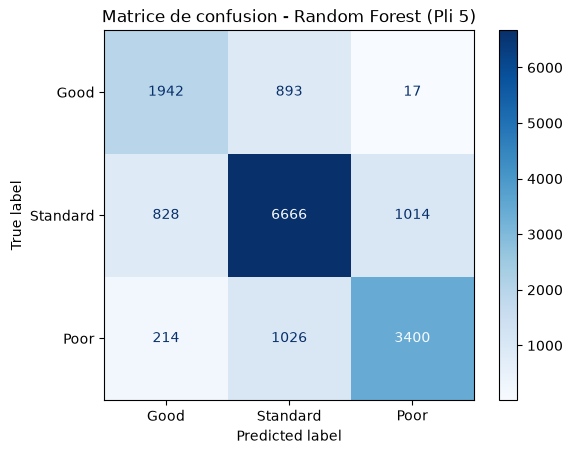

Résultats de la Validation Croisée enregistrés ou mis à jour dans le CSV avec succès !


In [15]:
#validation-croisée
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
import time
import os

# 1. Charger les données
x_train = pd.read_csv("../data/X_train_preprocessed.csv")
y_train = pd.read_csv("../data/y_train.csv")
x_val = pd.read_csv("../data/X_val_preprocessed.csv")
y_val = pd.read_csv("../data/y_val.csv")

# Préparer les classes 1D
y_train_1d = y_train["Credit_Score"]
y_val_1d = y_val["Credit_Score"]

# 2. Définir le découpage stratifié
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Instancier le modèle Random Forest
model_cv = RandomForestClassifier(n_estimators=30, max_depth=15, random_state=42, n_jobs=-1)

# Listes pour stocker les métriques de chaque pli
accuracies = []
f1_macros = []
f1_weighted_list = []

# Listes pour stocker les métriques par classe (pour faire la moyenne sur les plis)
prec_good_list, rec_good_list, f1_good_list = [], [], []
prec_std_list, rec_std_list, f1_std_list = [], [], []
prec_poor_list, rec_poor_list, f1_poor_list = [], [], []

temps_entrainement_total = 0
temps_prediction_total = 0

# Pour garder la dernière matrice de confusion en mémoire
derniers_y_vrai = None
derniers_y_pred = None

# 4. Boucler sur chaque pli
for fold, (train_idx, val_idx) in enumerate(cv_strategy.split(x_train, y_train_1d)):
    # Séparer les données pour ce pli
    X_f_train, X_f_val = x_train.iloc[train_idx], x_train.iloc[val_idx]
    y_f_train, y_f_val = y_train_1d.iloc[train_idx], y_train_1d.iloc[val_idx]
    
    # Entraîner et chronométrer l'entraînement
    debut = time.time()
    model_cv.fit(X_f_train, y_f_train)
    temps_entrainement_total += (time.time() - debut)
    
    # Prédire et chronométrer la prédiction
    debut = time.time()
    preds = model_cv.predict(X_f_val)
    temps_prediction_total += (time.time() - debut)
    
    # Sauvegarder pour la matrice de confusion finale
    derniers_y_vrai = y_f_val
    derniers_y_pred = preds
    
    # Calcul des métriques globales du pli
    acc = accuracy_score(y_f_val, preds)
    f1_m = f1_score(y_f_val, preds, average='macro')
    f1_w = f1_score(y_f_val, preds, average='weighted')
    
    accuracies.append(acc)
    f1_macros.append(f1_m)
    f1_weighted_list.append(f1_w)
    
    # --- Métriques par classe pour ce pli ---
    # Classe Good
    p_g = precision_score(y_f_val, preds, labels=["Good"], average='micro', zero_division=0) if "Good" in preds else 0
    r_g = recall_score(y_f_val, preds, labels=["Good"], average='micro', zero_division=0)
    f_g = f1_score(y_f_val, preds, labels=["Good"], average='micro', zero_division=0)
    
    # Classe Standard
    p_s = precision_score(y_f_val, preds, labels=["Standard"], average='micro', zero_division=0)
    r_s = recall_score(y_f_val, preds, labels=["Standard"], average='micro', zero_division=0)
    f_s = f1_score(y_f_val, preds, labels=["Standard"], average='micro', zero_division=0)
    
    # Classe Poor
    p_p = precision_score(y_f_val, preds, labels=["Poor"], average='micro', zero_division=0)
    r_p = recall_score(y_f_val, preds, labels=["Poor"], average='micro', zero_division=0)
    f_p = f1_score(y_f_val, preds, labels=["Poor"], average='micro', zero_division=0)
    
    # Stockage
    prec_good_list.append(p_g); rec_good_list.append(r_g); f1_good_list.append(f_g)
    prec_std_list.append(p_s); rec_std_list.append(r_s); f1_std_list.append(f_s)
    prec_poor_list.append(p_p); rec_poor_list.append(r_p); f1_poor_list.append(f_p)
    
    print(f"Pli {fold+1} -> Accuracy: {acc:.4f} | F1 Macro: {f1_m:.4f}")

# Calcul des moyennes globales sur les 5 plis
mean_accuracy = np.mean(accuracies)
mean_macro_f1 = np.mean(f1_macros)
mean_weighted_f1 = np.mean(f1_weighted_list)

mean_prec_good = np.mean(prec_good_list)
mean_recall_good = np.mean(rec_good_list)
mean_f1_good = np.mean(f1_good_list)

mean_prec_std = np.mean(prec_std_list)
mean_recall_std = np.mean(rec_std_list)
mean_f1_std = np.mean(f1_std_list)

mean_prec_poor = np.mean(prec_poor_list)
mean_recall_poor = np.mean(rec_poor_list)
mean_f1_poor = np.mean(f1_poor_list)

print("\n--- Résultats moyens de la Validation Croisée (Random Forest) ---")
print(f"Accuracy moyenne : {mean_accuracy:.4f}")
print(f"F1 Macro moyen : {mean_macro_f1:.4f}")
print(f"Temps d'entraînement total (cumulé) : {temps_entrainement_total:.4f}s")
print(f"Temps de prédiction total (cumulé) : {temps_prediction_total:.4f}s")

# 5. Afficher la matrice de confusion (sur le dernier pli évalué)
Cm = confusion_matrix(derniers_y_vrai, derniers_y_pred, labels=["Good", "Standard", "Poor"])
disp = ConfusionMatrixDisplay(confusion_matrix=Cm, display_labels=["Good", "Standard", "Poor"])
disp.plot(cmap="Blues")
plt.title("Matrice de confusion - Random Forest (Pli 5)")
plt.show()

# 6. Préparer les résultats moyens pour l'enregistrement
model_name = "model_RANDOM_FOREST-OPTIMISATION"
resultats = {
    "Modele": model_name,
    "Accuracy": mean_accuracy,
    "Precision_Good": mean_prec_good,
    "Recall_Good": mean_recall_good,
    "F1_Good": mean_f1_good,
    "Precision_Standard": mean_prec_std,
    "Recall_Standard": mean_recall_std,
    "F1_Standard": mean_f1_std,
    "Precision_Poor": mean_prec_poor,
    "Recall_Poor": mean_recall_poor,
    "F1_Poor": mean_f1_poor,
    "Macro_F1": mean_macro_f1,
    "Weighted_F1": mean_weighted_f1,
    "Temps_Entrainement": temps_entrainement_total,
    "Temps_Prediction": temps_prediction_total
}

# 7. Enregistrer dans le DataFrame et le fichier CSV
df = pd.DataFrame([resultats])
os.makedirs("../results", exist_ok=True)
fichier = "../results/resultats_modeles.csv"

if os.path.exists(fichier):
    ancien = pd.read_csv(fichier)
    ancien = ancien[ancien["Modele"] != model_name]
    df = pd.concat([ancien, df], ignore_index=True)

df.to_csv(fichier, index=False)
print("Résultats de la Validation Croisée enregistrés ou mis à jour dans le CSV avec succès !")

# Interprétation des résultas
   Principe de l'algorithme < Random Forest en Validation Croisée > :
* C'est un modèle d'apprentissage supervisé par ensemble (composé de multiples arbres de décision) qui combine leurs prédictions pour améliorer la robustesse, réduire le surapprentissage et mieux capturer la complexité des données.
* L'utilisation de la validation croisée stratifiée (StratifiedKFold à 5 plis) garantit une évaluation rigoureuse et objective en préservant la proportion des classes dans chaque sous-ensemble d'entraînement et de test.
   Matrice de confusion et Stabilité :
* Stabilité inter-plis : Le modèle fait preuve d'une excellente régularité, avec des scores d'Accuracy extrêmement stables d'un pli à l'autre, oscillant entre "74.99%" et "75.35%".
* Temps d'exécution : Le processus présente un temps d'entraînement total cumulé de "8,17" secondes pour un temps de prédiction ultra-rapide de "0,25" seconde, ce qui montre un bon compromis entre complexité et rapidité.
* Analyse de la matrice < Pli 5 >: Sur ce pli, le modèle classe correctement la grande majorité des instances ("1942" pour Good, "6666" pour Standard et "3400" pour Poor). Les principales confusions se produisent entre la classe Standard et les deux autres (par exemple, "828" instances Standard classées à tort en Good et "1014" en Poor).
   Performances :
* Accuracy moyenne : S'élève à "0,7512" (75,12%), traduisant une nette progression et des performances supérieures par rapport à un Arbre de décision isolé ou un classifieur naïf.  
* F1 Macro moyen : Atteint "0,7322" (73.22%), confirmant que le modèle gère l'ensemble des classes de manière équilibrée malgré les déséquilibres initiaux du dataset.
* Classe Standard : Enregistre le plus grand volume de bonnes prédictions " 6666" en raison de sa surreprésentation dans les données, mais centralise aussi l'essentiel des confusions du modèle.  
* Classes Good et Poor : Maintiennent des taux de reconnaissance solides <"1942" et "3400" bonnes classifications>, avec une légère porosité frontalière vers la classe médiane Standard.
 

# la Recherche d'hyperparamètres "GridSearchCV"

Fitting 5 folds for each of 48 candidates, totalling 240 fits

Meilleurs hyperparamètres trouvés : {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Meilleur score F1 Macro (durant le Grid Search) : 0.7880
Temps d'entraînement (Grid Search) : 1752.5589s
Temps de prédiction : 0.7589s


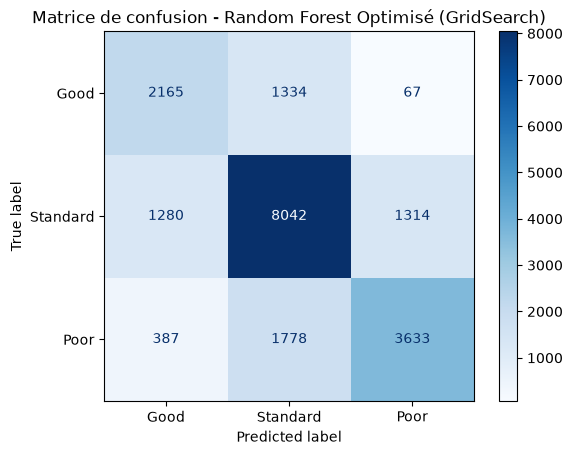

Résultats du Random Forest optimisé enregistrés ou mis à jour dans le CSV avec succès !


In [16]:
#gridsearchCV
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
import time
import os

# 1. Charger les données
x_train = pd.read_csv("../data/X_train_preprocessed.csv")
y_train = pd.read_csv("../data/y_train.csv")
x_val = pd.read_csv("../data/X_val_preprocessed.csv")
y_val = pd.read_csv("../data/y_val.csv")

# Préparer les classes 1D
y_train_1d = y_train["Credit_Score"]
y_val_1d = y_val["Credit_Score"]

# 2. Instancier le modèle de base et configurer la grille
model_base = RandomForestClassifier(random_state=42, n_jobs=-1)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=model_base,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# 3. Entraîner et chronométrer la recherche des meilleurs hyperparamètres
debut = time.time()
grid_search.fit(x_train, y_train_1d)
temps_entrainement = time.time() - debut

print("\nMeilleurs hyperparamètres trouvés :", grid_search.best_params_)
print(f"Meilleur score F1 Macro (durant le Grid Search) : {grid_search.best_score_:.4f}")
print(f"Temps d'entraînement (Grid Search) : {temps_entrainement:.4f}s")

# Récupérer le meilleur modèle optimisé
best_model_rf = grid_search.best_estimator_

# 4. Prédire et chronométrer sur le jeu de validation
debut = time.time()
y_pred = best_model_rf.predict(x_val)
temps_prediction = time.time() - debut
print(f"Temps de prédiction : {temps_prediction:.4f}s")

# 5. Calcul des indicateurs de performance
accuracy = accuracy_score(y_val_1d, y_pred)
macro_f1 = f1_score(y_val_1d, y_pred, average='macro')
weighted_f1 = f1_score(y_val_1d, y_pred, average='weighted')

# Métriques par classe
nombre_good = (y_val_1d == "Good").sum()
precision_good = precision_score(y_val_1d, y_pred, labels=["Good"], average='micro', zero_division=0) if "Good" in y_pred else 0
recall_good = recall_score(y_val_1d, y_pred, labels=["Good"], average='micro', zero_division=0)
f1_good = f1_score(y_val_1d, y_pred, labels=["Good"], average='micro', zero_division=0)

nombre_standard = (y_val_1d == "Standard").sum()
precision_standard = precision_score(y_val_1d, y_pred, labels=["Standard"], average='micro', zero_division=0)
recall_standard = recall_score(y_val_1d, y_pred, labels=["Standard"], average='micro', zero_division=0)
f1_standard = f1_score(y_val_1d, y_pred, labels=["Standard"], average='micro', zero_division=0)

nombre_poor = (y_val_1d == "Poor").sum()
precision_poor = precision_score(y_val_1d, y_pred, labels=["Poor"], average='micro', zero_division=0)
recall_poor = recall_score(y_val_1d, y_pred, labels=["Poor"], average='micro', zero_division=0)
f1_poor = f1_score(y_val_1d, y_pred, labels=["Poor"], average='micro', zero_division=0)

# 6. Afficher la matrice de confusion
Cm = confusion_matrix(y_val_1d, y_pred, labels=["Good", "Standard", "Poor"])
disp = ConfusionMatrixDisplay(confusion_matrix=Cm, display_labels=["Good", "Standard", "Poor"])
disp.plot(cmap="Blues")
plt.title("Matrice de confusion - Random Forest Optimisé (GridSearch)")
plt.show()

# 7. Préparer et enregistrer les résultats dans le fichier CSV
model_name = "model_RANDOM_FOREST_GRIDSEARCH"
resultats = {
    "Modele": model_name,
    "Accuracy": accuracy,
    "Precision_Good": precision_good,
    "Recall_Good": recall_good,
    "F1_Good": f1_good,
    "Precision_Standard": precision_standard,
    "Recall_Standard": recall_standard,
    "F1_Standard": f1_standard,
    "Precision_Poor": precision_poor,
    "Recall_Poor": recall_poor,
    "F1_Poor": f1_poor,
    "Macro_F1": macro_f1,
    "Weighted_F1": weighted_f1,
    "Temps_Entrainement": temps_entrainement,
    "Temps_Prediction": temps_prediction
}

df = pd.DataFrame([resultats])
os.makedirs("../results", exist_ok=True)
fichier = "../results/resultats_modeles.csv"

if os.path.exists(fichier):
    ancien = pd.read_csv(fichier)
    ancien = ancien[ancien["Modele"] != model_name]
    df = pd.concat([ancien, df], ignore_index=True)

df.to_csv(fichier, index=False)
print("Résultats du Random Forest optimisé enregistrés ou mis à jour dans le CSV avec succès !")

# Interprétation des résultas
   Principe de l'Optimisation par GridSearch :
* C'est une technique d'optimisation par recherche exhaustive sur grille combinée à une validation croisée <5 plis, soit "240" ajustements de modèles au total>. Elle permet d'explorer différentes combinaisons d'hyperparamètres afin de sélectionner automatiquement la configuration optimale maximisant le score F1 Macro. 
*  Les meilleurs hyperparamètres retenus sont une profondeur maximale non limitée < max_depth: None>, sans restriction stricte sur les feuilles ou les divisions < min_samples_leaf: 1, min_samples_split: 2>, permettant à l'ensemble des arbres de capturer finement la complexité des données.  
   Matrice de confusion et Temps d'exécution :
* Temps d'entraînement et de prédiction : La phase d'optimisation et d'apprentissage a nécessité un temps d'entraînement important de "1752,56" secondes < en raison de l'exploration de la grille sur les 5 plis>, pour un temps de prédiction final très rapide de "0,76" seconde. 
*  Répartition des prédictions : Le modèle classifie correctement un volume élevé d'instances avec 2165 bonnes prédictions pour Good, 8042 pour Standard et 3633 pour Poor.  
* Analyse des erreurs : Les confusions restent concentrées autour de la classe Standard, avec par exemple "1280" instances Standard prédites à tort en Good et "1314" en Poor, ainsi que "1778" instances Poor confondues avec du Standard.  
   Performances globales :
* Score F1 Macro (GridSearch) : Atteint un niveau record de "0,7880" (78,80%), ce qui démontre l'efficacité supérieure de l'optimisation par rapport au modèle par défaut. 
   Comparaison : 
* Cet affinement des hyperparamètres permet de surpasser nettement les performances de l'Arbre de décision isolé et du Random Forest de base, confirmant que l'approche optimisée offre la meilleure capacité de généralisation et de discrimination des classes pour ce projet de classification du score de crédit.

# Conculsion et choix final
 * Le choix du modèle final:
Le modèle retenu et validé comme solution finale pour la classification du score de crédit est le Random Forest Optimisé (via GridSearchCV).
 * la justification :
  - Supériorité des performances : Le Random Forest optimisé surclasse nettement les autres approches testées, en atteignant un score F1
Macro de 78,80%, surpassant le Random Forest de base (~73,22%) et l'Arbre de décision unique (~59%). 
  - Robustesse et stabilité : Grâce à la combinaison de multiples arbres de décision et à l'ajustement fin des hyperparamètres, il réduit
efficacement le surapprentissage (overfitting) et gère de manière plus homogène les variations entre les différentes classes de crédit (Good, Standard, Poor).
  - Compromis opérationnel : Malgré un temps d'entraînement plus long induit par la recherche exhaustive, le modèle final conserve un
temps de prédiction ultra-rapide (0,76 s), ce qui le rend parfaitement viable pour un déploiement opérationnel en entreprise.   
 * limites et perspectives :
  - Limites :
 Le coût computationnel et le temps de calcul élevés requis pour la phase d'optimisation par GridSearch.
 La complexité de la structure en "forêt" rend l'interprétabilité visuelle plus délicate comparée à un unique Arbre de décision transparent.
  - Perspectives :
Explorer d'autres algorithmes de boosting avancés (tels que XGBoost, LightGBM ou CatBoost) pour tenter d'optimiser davantage les performances.
Mettre en place des techniques de rééquilibrage des données (comme SMOTE) pour améliorer la prédiction des classes minoritaires.
Intégrer un processus de sélection de caractéristiques (Feature Selection) plus poussé pour réduire la dimensionnalité du jeu de données.
